# Understanding the vehicle readings

An engine, brake or battery issue can interrupt a journey. In this project, I study whether sensor readings can help distinguish ordinary operation from readings labelled with one of these issues.

I begin with the data. What does a reading contain? How many issue examples are available? Do their sensor values look different? These questions help explain the modelling choices that follow.


## Data and libraries

The analysis uses Python for data preparation, modelling and visualization. The dataset and saved results share one project folder. Colab stores this folder in Google Drive, while a local Jupyter session uses the same layout.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
from importlib.metadata import version, PackageNotFoundError
from urllib.request import urlretrieve

packages = {
    "numpy": "2.2.6", "pandas": "2.3.3", "scipy": "1.16.2",
    "scikit-learn": "1.7.2", "xgboost": "3.0.5",
    "imbalanced-learn": "0.14.0", "matplotlib": "3.10.6",
    "seaborn": "0.13.2", "openpyxl": "3.1.5", "joblib": "1.6.0"
}
install = []
for package, required in packages.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    if installed != required:
        install.append(f"{package}=={required}")
loaded_libraries = any(name in sys.modules for name in [
    "numpy", "pandas", "scipy", "sklearn", "matplotlib", "seaborn",
    "xgboost", "imblearn", "joblib", "openpyxl"
])
if install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *install])
    if loaded_libraries:
        raise SystemExit(
            "Libraries updated. Choose Runtime > Restart session, then Run all. "
            "In local Jupyter, restart the kernel and run all cells."
        )

for package, module in [("numpy", "numpy"), ("pandas", "pandas"),
                        ("scipy", "scipy"), ("scikit-learn", "sklearn")]:
    loaded = sys.modules.get(module)
    if loaded is not None and getattr(loaded, "__version__", None) != version(package):
        raise SystemExit(
            "A previous library version is still loaded. "
            "Restart the session or kernel, then run all cells."
        )

try:
    from google.colab import drive
except ImportError:
    project = Path.cwd()
    if project.name == "notebooks":
        project = project.parent
else:
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/Automotive_Component_Failure")

for folder in ["data", "models/baseline", "models/follow_up",
               "results/tables", "results/figures", "results/predictions", "results/recorded"]:
    (project / folder).mkdir(parents=True, exist_ok=True)

source = "https://raw.githubusercontent.com/PrasadKolkar/critical-automotive-component-failure/main"
files = {
    "data/synthetic_telemetry_data.xlsx": "data/synthetic_telemetry_data.xlsx",
    "data/vehicle_folds.csv": "data/vehicle_folds.csv"
}
for name in ["model_comparison.csv", "oof_predictions.csv", "representation_comparison.csv",
             "augmentation_comparison.csv", "confusion_counts.csv"]:
    files["results/recorded/" + name] = "results/recorded/" + name
for name in ["feature_importance.csv", "descriptive_subtype_rules.json", "reconstruction_comparison.json"]:
    files["results/recorded/" + name] = "results/recorded/" + name
for destination, original in files.items():
    if not (project / destination).exists():
        temporary = (project / destination).with_suffix(".download")
        urlretrieve(f"{source}/{original}", temporary)
        temporary.replace(project / destination)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
figures = project / "results/figures"
tables = project / "results/tables"
recorded = project / "results/recorded"
print("Project files ready.")


Project files ready.


In [2]:
data_path = project / "data/synthetic_telemetry_data.xlsx"
fold_path = project / "data/vehicle_folds.csv"
expected_hashes = {
    data_path: "569d9f3bfd57f25e2ee7b0d4176fd22b8b8e4aa9a1cf5dab30b57517a4950cc3",
    fold_path: "3f9d35b1ba22f124fe4ef11da399b1abe6d8978257025e5cbe7b79b4422b4b1e"
}
for path, expected in expected_hashes.items():
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        raise ValueError(f"The study file has changed: {path.name}")

df = pd.read_excel(data_path)
component_labels = ["engine_failure_imminent", "brake_issue_imminent", "battery_issue_imminent"]
target = "any_imminent_issue"
df[target] = df[component_labels].max(axis=1).astype(int)
vehicle_folds = pd.read_csv(fold_path)
fold_for_row = df.vehicle_id.map(vehicle_folds.set_index("vehicle_id").fold)
assert vehicle_folds.vehicle_id.is_unique
assert set(vehicle_folds.vehicle_id) == set(df.vehicle_id)
assert len(df) == 1970 and df.vehicle_id.nunique() == 50 and df[target].sum() == 35
assert not fold_for_row.isna().any()
print(f"{len(df):,} readings from {df.vehicle_id.nunique()} vehicles")
print(f"{df[target].sum()} issue-labelled readings from {df.loc[df[target].eq(1), 'vehicle_id'].nunique()} vehicles")


1,970 readings from 50 vehicles
35 issue-labelled readings from 25 vehicles


## A first look

The workbook contains 1,970 readings from 50 vehicles and 41 original fields. Each vehicle appears several times. The combined issue label adds one column for the analysis.


In [3]:
display(df.head())
display(df[pd.Index(df.columns).difference([target])].describe(include="all").T)


,vehicle_id,brand,timestamp,odometer_reading,engine_temp_c,engine_rpm,oil_pressure_psi,coolant_temp_c,fuel_level_percent,fuel_consumption_lph,...,ambient_temp_c,humidity_percent,gps_latitude,gps_longitude,engine_failure_imminent,brake_issue_imminent,battery_issue_imminent,failure_date,failure_type,any_imminent_issue
0,VEH0000,BMW,2023-01-01 00:00:00,31381.561743,99.388213,2212.155243,55.522505,91.788105,68.368162,4.076315,...,24.187057,83.785796,31.986296,78.203395,0,0,0,2050-01-01,No Failure,0
1,VEH0000,BMW,2023-01-01 00:56:00,31391.284155,84.118706,961.795251,57.799346,87.283282,99.064394,7.059168,...,15.148875,57.418501,30.620539,84.389727,0,0,0,2050-01-01,No Failure,0
2,VEH0000,BMW,2023-01-01 01:28:00,31428.088015,103.521431,742.050437,50.398848,83.503155,80.280244,10.792362,...,23.138714,80.540135,30.634997,79.039234,0,0,0,2050-01-01,No Failure,0
3,VEH0000,BMW,2023-01-01 01:27:00,31463.271669,91.130527,2723.042461,41.719715,90.997963,13.892586,1.564630,...,35.058947,57.221563,33.490971,76.107248,0,0,0,2050-01-01,No Failure,0
4,VEH0000,BMW,2023-01-01 01:00:00,31490.411858,96.887263,2647.979969,38.438964,93.029011,20.871931,6.814662,...,18.024207,47.680115,28.392300,83.160007,0,0,0,2050-01-01,No Failure,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
abs_fault_indicator,1970.0,NaN,NaN,NaN,0.111675,0.0,0.0,0.0,0.0,1.0,0.315046
air_flow_rate_gps,1970.0,NaN,NaN,NaN,50.292807,0.0,36.97298,50.179637,64.408787,106.856022,19.670713
alternator_output_v,1970.0,NaN,NaN,NaN,14.197447,13.110096,14.007229,14.206,14.394783,15.241447,0.292889
ambient_temp_c,1970.0,NaN,NaN,NaN,29.966583,-17.116179,23.609246,30.271354,36.709522,63.348462,9.867784
battery_charge_percent,1970.0,NaN,NaN,NaN,70.092167,40.01829,55.096188,70.652447,84.273524,99.96843,17.161083
battery_current_a,1970.0,NaN,NaN,NaN,10.090152,-67.829694,-3.473606,10.737516,24.296475,83.362796,21.207427
battery_health_percent,1970.0,NaN,NaN,NaN,94.329009,90.162163,91.960024,94.17295,96.249211,99.386264,2.541468
battery_issue_imminent,1970.0,NaN,NaN,NaN,0.006091,0.0,0.0,0.0,0.0,1.0,0.077829
battery_temp_c,1970.0,NaN,NaN,NaN,25.003929,6.669371,21.49498,25.002662,28.411607,42.367341,5.098852
battery_voltage_v,1970.0,NaN,NaN,NaN,12.578856,9.065082,12.266905,12.595619,12.928926,14.524733,0.531746


## How common are the issues?

Only 35 readings carry an issue label. Those readings come from 25 vehicles. I expect accuracy alone to hide some mistakes because ordinary readings greatly outnumber issue readings.


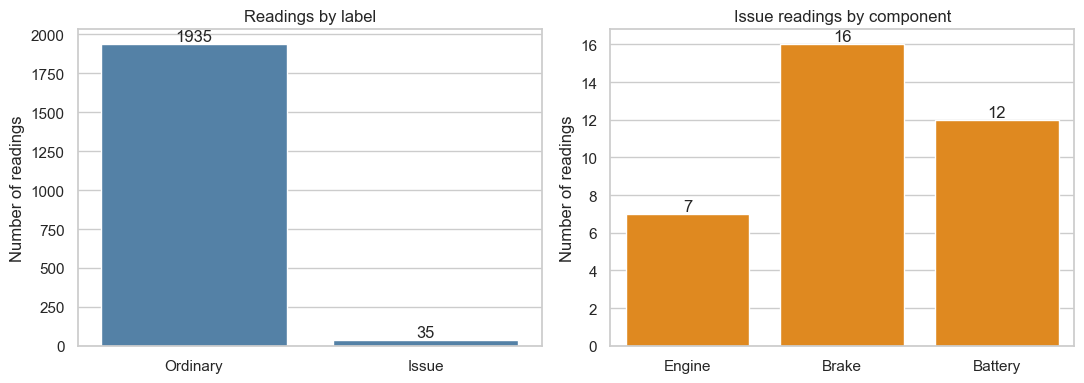

Predicting every reading as ordinary gives 98.22% accuracy and finds no issues.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = df[target].value_counts().reindex([0, 1])
sns.barplot(x=["Ordinary", "Issue"], y=counts.values, ax=axes[0], color="steelblue")
axes[0].set(title="Readings by label", ylabel="Number of readings")
subtypes = df[component_labels].sum()
sns.barplot(x=["Engine", "Brake", "Battery"], y=subtypes.values, ax=axes[1], color="darkorange")
axes[1].set(title="Issue readings by component", ylabel="Number of readings")
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
plt.tight_layout()
plt.savefig(figures / "class_balance.png", dpi=180)
plt.show()
print(f"Predicting every reading as ordinary gives {(df[target].eq(0).mean() * 100):.2f}% accuracy and finds no issues.")


There are seven engine, 16 brake and 12 battery readings. I combine the three issue types for the main classification task. A separate comparison for each component would have very few positive examples.


## Checking the data quality

I check missing values, repeated records and measurements that need a closer look. I keep the original readings because the workbook does not provide a reliable correction rule.


In [5]:
wheel_columns = [c for c in df.columns if c.startswith("wheel_speed_")]
quality = {
    "Missing cells": int(df.isna().sum().sum()),
    "Fully duplicated rows": int(df.drop(columns=target).duplicated().sum()),
    "Extra rows with a repeated vehicle and time": int(df.duplicated(["vehicle_id", "timestamp"]).sum()),
    "Repeated vehicle/time groups": int(df.groupby(["vehicle_id", "timestamp"]).size().gt(1).sum()),
    "Humidity above 100%": int(df.humidity_percent.gt(100).sum()),
    "Negative vibration": int(df.vibration_level.lt(0).sum())
}
quality.update({"Negative " + column: int(df[column].lt(0).sum()) for column in wheel_columns})
display(pd.Series(quality, name="Count").to_frame())
display(df.groupby("vehicle_id").size().describe().to_frame("Readings per vehicle"))
pd.Series(quality).to_csv(tables / "data_quality.csv")


,Count
Missing cells,0
Fully duplicated rows,0
Extra rows with a repeated vehicle and time,40
Repeated vehicle/time groups,39
Humidity above 100%,4
Negative vibration,1
Negative wheel_speed_fl_kph,50
Negative wheel_speed_fr_kph,52
Negative wheel_speed_rl_kph,37
Negative wheel_speed_rr_kph,48


,Readings per vehicle
count,50.000000
mean,39.400000
std,3.251373
min,35.000000
25%,36.250000
50%,39.000000
75%,42.750000
max,44.000000


The data contain no missing cells or fully duplicated rows. Some vehicle/time combinations repeat. Negative wheel speeds and a few other unusual values also need caution. A negative wheel speed might reflect direction or a simulator convention; that convention is not documented.


## Looking at the sensor distributions

I first look at the range and shape of six measurements. Histograms make it easier to spot common values and the smaller groups near the ends.


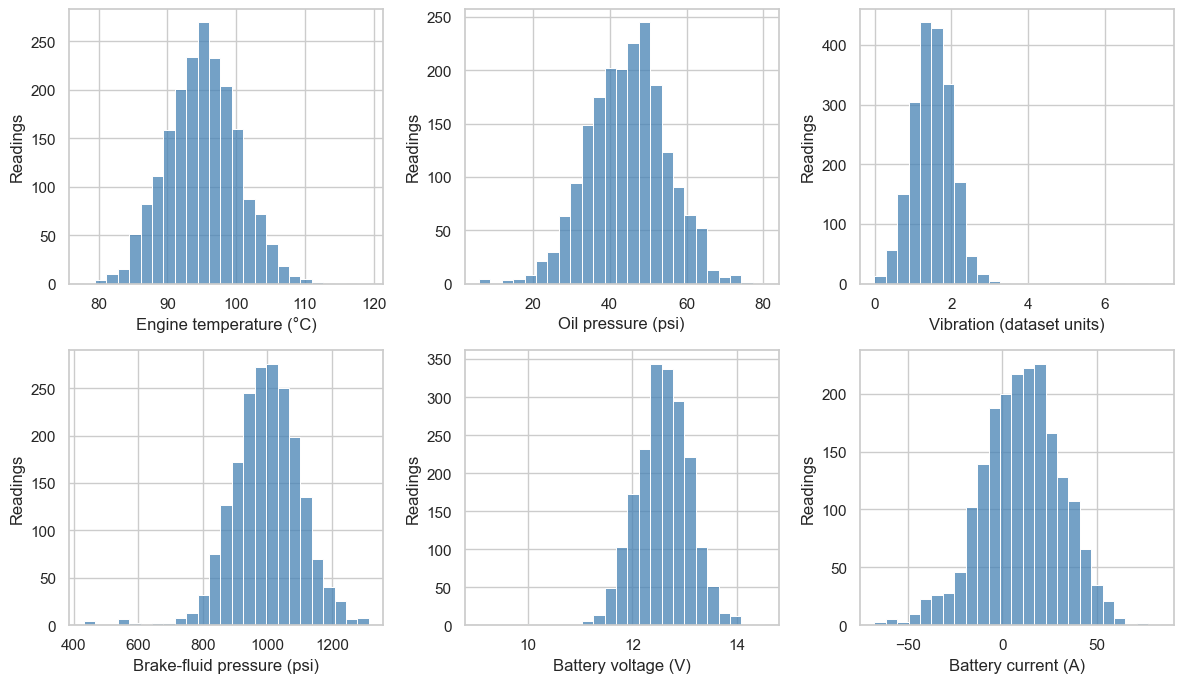

In [6]:
sensors = ["engine_temp_c", "oil_pressure_psi", "vibration_level",
           "brake_fluid_level_psi", "battery_voltage_v", "battery_current_a"]
labels = ["Engine temperature (°C)", "Oil pressure (psi)", "Vibration (dataset units)",
          "Brake-fluid pressure (psi)", "Battery voltage (V)", "Battery current (A)"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, sensor, label in zip(axes.flat, sensors, labels):
    sns.histplot(data=df, x=sensor, bins=25, ax=ax, color="steelblue")
    ax.set(xlabel=label, ylabel="Readings")
plt.tight_layout()
plt.savefig(figures / "sensor_distributions.png", dpi=180)
plt.show()


Most readings lie in the middle of these distributions. The pressure, voltage and temperature values have different units and ranges. This is why I scale numerical inputs for models that depend on distance or feature size.


## Comparing component labels with sensor values

I expect oil pressure to help distinguish engine issues. Brake-fluid pressure may help identify brake issues, while voltage may help identify battery issues. I compare each component label with its corresponding measurement.


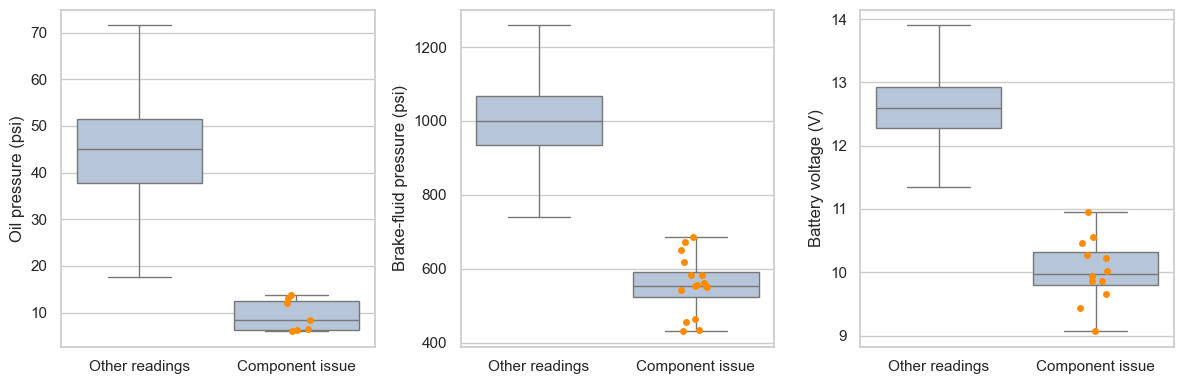

In [7]:
comparisons = [("oil_pressure_psi", "engine_failure_imminent", "Oil pressure (psi)"),
               ("brake_fluid_level_psi", "brake_issue_imminent", "Brake-fluid pressure (psi)"),
               ("battery_voltage_v", "battery_issue_imminent", "Battery voltage (V)")]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (sensor, label, unit) in zip(axes, comparisons):
    sns.boxplot(data=df, x=label, y=sensor, showfliers=False, ax=ax, color="lightsteelblue")
    sns.stripplot(data=df.loc[df[label].eq(1)], x=label, y=sensor, order=[0, 1], ax=ax, color="darkorange", size=5)
    ax.set(xlabel="", ylabel=unit, xticks=[0, 1], xticklabels=["Other readings", "Component issue"])
plt.tight_layout()
plt.savefig(figures / "component_sensors.png", dpi=180)
plt.show()


The issue groups have lower typical oil pressure, brake-fluid pressure and voltage. These patterns explain why those measurements deserve attention. The small groups make the summaries sensitive to individual readings.


## Do the sensors move together?

A correlation heatmap shows whether two measurements tend to rise or fall together. I use selected sensor inputs here. Values near zero indicate weak linear relationships.


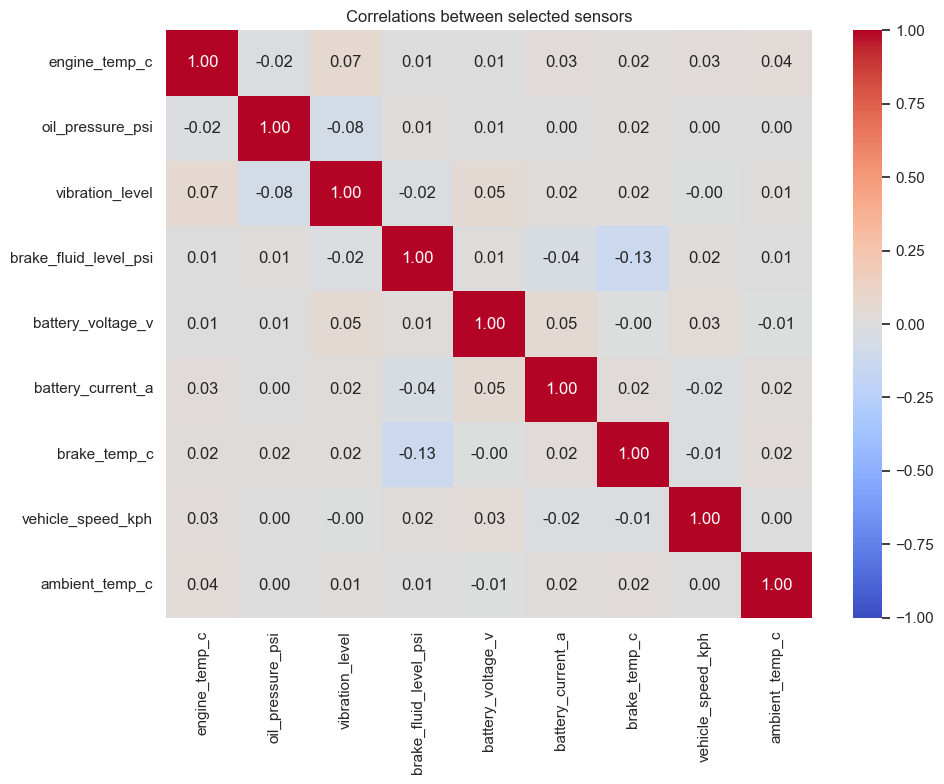

In [8]:
correlation_columns = sensors + ["brake_temp_c", "vehicle_speed_kph", "ambient_temp_c"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlations between selected sensors")
plt.tight_layout()
plt.savefig(figures / "sensor_correlations.png", dpi=180)
plt.show()


The off-diagonal correlations are weak. This describes relationships between sensors. It does not rule out a sensor cutoff being useful for distinguishing issue labels. I therefore compare both linear and nonlinear models.


## Choosing the inputs and vehicle groups

The failure date uses 2050-01-01 for ordinary readings. A model could use that field to recognize the answer directly. I exclude failure metadata and component flags from the predictors. I also examine the ABS indicator separately.

Each test group keeps whole vehicles together. This asks whether the learned patterns carry over to other vehicles from the same synthetic source.


In [9]:
display(pd.crosstab(df[target], pd.to_datetime(df.failure_date).eq(pd.Timestamp("2050-01-01")),
                    rownames=["Issue label"], colnames=["Failure date is 2050-01-01"]))
summary = pd.DataFrame({"fold": fold_for_row, "vehicle": df.vehicle_id, "issue": df[target]})
display(summary.groupby("fold").agg(readings=("vehicle", "size"), vehicles=("vehicle", "nunique"), issues=("issue", "sum")))


Failure date is 2050-01-01,False,True
Issue label,,
0,0,1935
1,35,0


,readings,vehicles,issues
fold,,,
1,396,10,7
2,396,10,7
3,393,10,7
4,393,10,7
5,392,10,7


## What I take into modelling

The main task is to distinguish ordinary readings from issue-labelled readings. I combine the three issue types, keep the original measurements, and exclude fields that state the outcome.

The next notebook compares six model families using the same vehicle groups. I judge them by the issues found, the false alerts and their ranking of issue readings. The workbook's synthetic labels support this comparison; real warning time would need confirmed failure histories.
